[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB14c_seizure_and_stimulation.ipynb)

# Day 2 · Chapter 5 · Notebook 14c — A seizure in the model, and a stimulation to stop it

About a third of people with epilepsy are not helped by drugs. For them, doctors must decide which tissue to remove
(surgery) or where and when to stimulate. **Virtual Epileptic Patient** models, built on each patient's connectome, are
used to test these choices before touching the patient (Jirsa et al. 2017). Here, a minimal version.

> **Question.** Can stimulation stop a seizure that spreads over the connectome, and at what cost?
> **Virtual experiment.** The same epileptic brain and the same noise, untreated and with two stimulation strategies.
> **What would change our mind.** If a single pulse stopped the seizure for good, closed-loop stimulation would not be
> needed.

We make a few regions of the bistable model of NB11 **more excitable**, watch activity ignite in one of them and spread
to its neighbours (a seizure-like event), then try to stop it.

<details><summary>The set-up (Virtual Epileptic Patient)</summary>

Each region is a spiking population of NB05/NB11 with a quiet **down** and an active **up** state; its excitability
$\eta$ sets how easily it switches up. Following the Virtual Epileptic Patient approach (Jirsa et al. 2017):
* **focus** (left temporal pole, a classic site of epilepsy): $\eta=-3.3$, much more excitable than normal;
* **propagation zone**: its six most strongly connected regions, $\eta=-3.9$, slightly more excitable;
* all other regions: healthy, $\eta=-4.3$ as in NB11; global coupling $G=0.5$, weaker than NB11's 0.7, so that the
  healthy brain stays quiet (no region switches up by itself) and every event comes from the epileptic regions.

The four 20-s simulations are pre-run (`dev/cache_nb14c_seizure.py`); this notebook only plots them.
</details>

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="max", homotopic=0.5)      # same connectome as NB11 (scaled to a maximum of 1)
labels = [l.replace("7Networks_", "") for l in labels]
cache = np.load("../data/cache/nb14c_seizure.npz")
names, rates, stim = list(cache["names"]), cache["rates"], cache["stim"]   # 4 scenarios x time x regions (every 5 ms)
FOCUS, PZ, dt = int(cache["focus"]), list(cache["pz"]), float(cache["dt"])
t = np.arange(rates.shape[1]) * dt
rows = [FOCUS] + PZ + [i for i in range(100) if i != FOCUS and i not in PZ]   # focus and propagation zone at the top
UP = 0.4                                                                    # firing rate above which a region is "up"
print("focus:", labels[FOCUS]); print("propagation zone:", [labels[i] for i in PZ])

def raster(ax, r, title, n=30, stim_on=None):
    # firing rate of the focus, the propagation zone and the first healthy regions (one row each)
    im = ax.imshow(r[:, rows[:n]].T, aspect="auto", cmap="magma", vmin=0, vmax=1.5, extent=[0, t[-1], n, 0], interpolation="nearest")
    ax.axhline(0.98, c="w", lw=0.8); ax.axhline(6.98, c="w", lw=0.8)
    ax.set_yticks([0.5, 4, 18], ["focus", "propagation\nzone", "healthy\nregions"], fontsize=8); ax.set_title(title, fontsize=10)
    if stim_on is not None and stim_on.any():
        ax.fill_between(t, n - 1.5, n, where=stim_on, color="c", step="post")
    return im

focus: LH_Limbic_TempPole_1
propagation zone: ['RH_Limbic_TempPole_1', 'LH_SalVentAttn_FrOperIns_1', 'LH_Vis_1', 'LH_Default_Temp_1', 'LH_Limbic_TempPole_2', 'LH_DorsAttn_Post_1']


## 1. A seizure starts and spreads

In the healthy brain every region stays down. In the epileptic brain the focus switches up **by itself**, and then, one
after the other, the regions of the propagation zone are dragged up too. What we watch is the **spread** of a seizure,
not its onset: the focus is so excitable that it ignites at once.

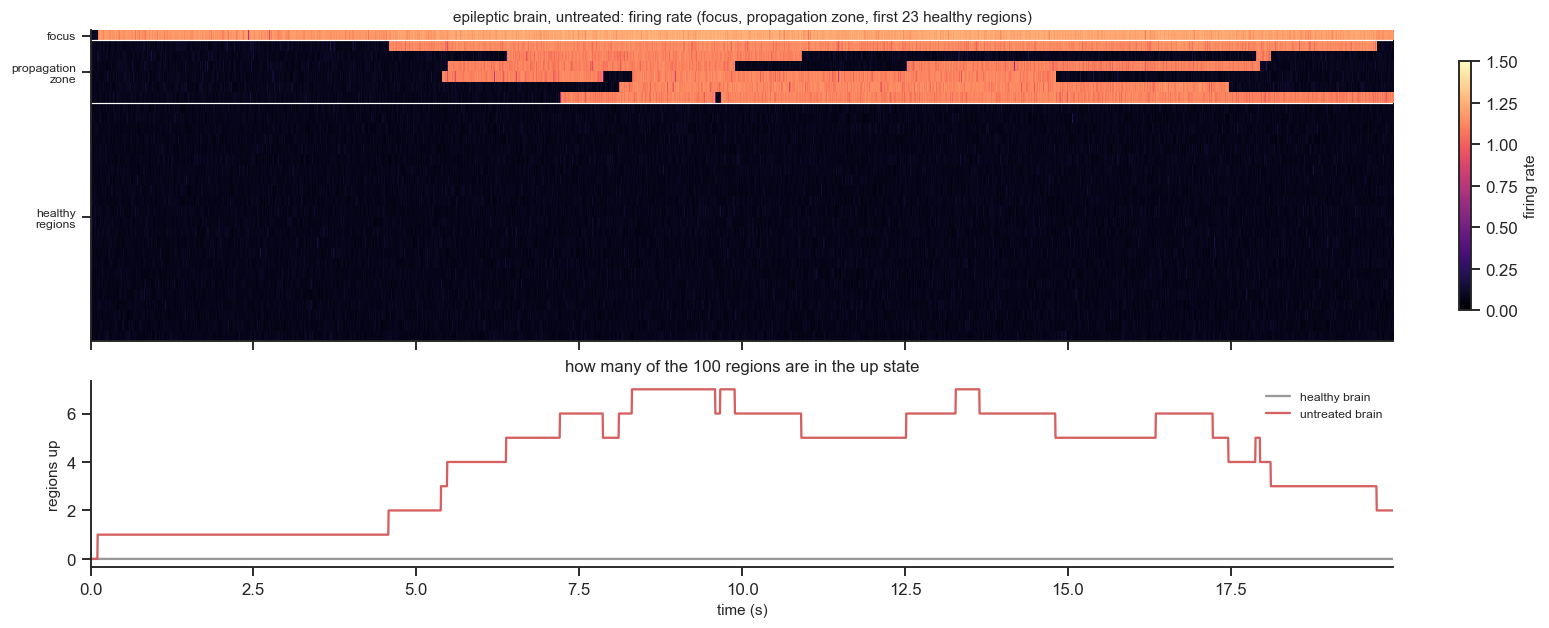

In [2]:
# @title Raster of the untreated epileptic brain, and number of regions up (healthy vs epileptic)
fig, ax = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 0.6]), layout="constrained")
im = raster(ax[0], rates[names.index("untreated")], "epileptic brain, untreated: firing rate (focus, propagation zone, first 23 healthy regions)")
fig.colorbar(im, ax=ax[0], label="firing rate", shrink=0.8)
for n_, c in [("healthy", "0.6"), ("untreated", "C3")]:
    ax[1].plot(t, (rates[names.index(n_)] > UP).sum(1), c=c, lw=1.5, label=f"{n_} brain")
ax[1].set(xlabel="time (s)", ylabel="regions up", title="how many of the 100 regions are in the up state"); ax[1].legend(fontsize=8)
plt.show()

The focus ignites within the first 0.1 s and stays up for the whole 20 s: a seizure that does not end by itself. Over
the next 5–8 s it **spreads along the strongest connections** into the propagation zone, one region at a time, and
those regions stay up for long stretches (in a bistable region the up state sustains itself). It stops at healthy tissue, whose down state is deep enough
to resist. In the healthy brain (grey line) no region switches up.

<details><summary>Caveat: what "seizure" means here</summary>

Here a seizure is a group of regions locked in a high-activity state. Real seizures also have characteristic rhythmic
discharges; models built for them (the Epileptor, Jirsa et al. 2014) reproduce those too. The logic of spreading through
the connectome is the same.
</details>

## 2. Two ways to stimulate

* **One pulse:** at $t=10$ s, one strong inhibitory pulse (300 ms) to the focus and the propagation zone.
* **Responsive stimulation:** watch the focus and, **as soon as it switches up**, inhibit it (focus only, 300 ms). This
  is the idea of closed-loop neurostimulation used in drug-resistant epilepsy (Morrell 2011).

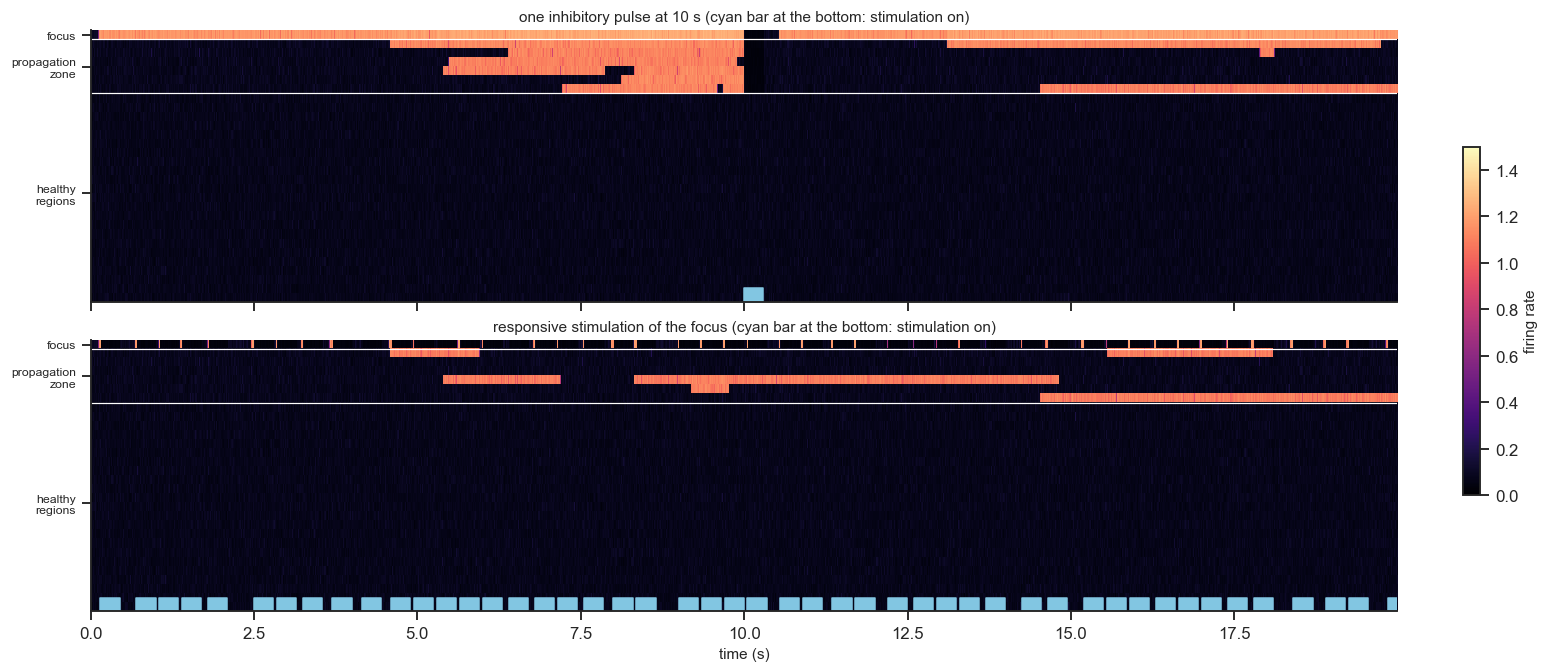

In [3]:
# @title Rasters with one inhibitory pulse and with responsive stimulation (cyan: stimulation on)
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, layout="constrained")
for a_, name, title in [(ax[0], "one pulse", "one inhibitory pulse at 10 s"), (ax[1], "responsive", "responsive stimulation of the focus")]:
    k = names.index(name); im = raster(a_, rates[k], f"{title} (cyan bar at the bottom: stimulation on)", stim_on=stim[k])
fig.colorbar(im, ax=ax, label="firing rate", shrink=0.6); ax[1].set_xlabel("time (s)")
plt.show()

**One pulse** switches every region down at once and the seizure stops, but the focus is still too excitable: within a
second it switches up again and a new seizure spreads. **Responsive stimulation** catches the focus each time it
ignites, so it never stays up; a few regions of the propagation zone still switch up now and then on their own.

## 3. What each strategy costs

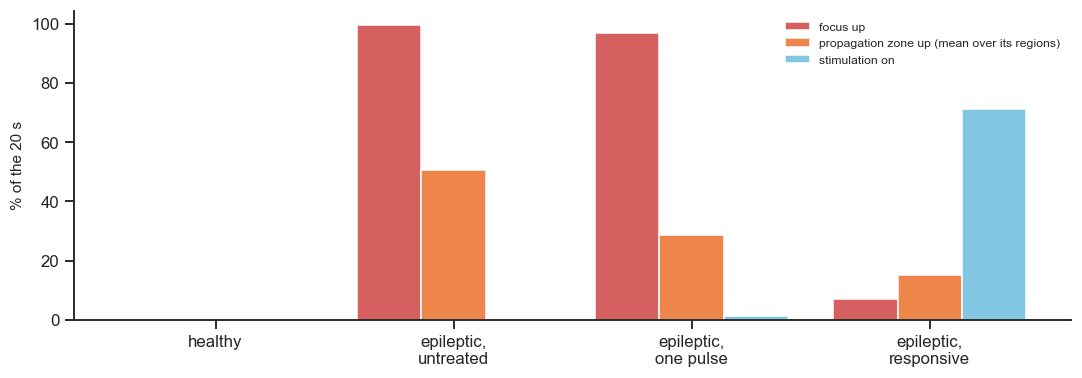

healthy     focus up   0 %, zone up   0 %, stimulation   0 %
untreated   focus up  99 %, zone up  51 %, stimulation   0 %
one pulse   focus up  97 %, zone up  29 %, stimulation   2 %
responsive  focus up   7 %, zone up  15 %, stimulation  71 %


In [4]:
# @title Fraction of time the focus and the propagation zone are up, and the stimulator is on
focus_up = [100 * (r[:, FOCUS] > UP).mean() for r in rates]
pz_up = [100 * (r[:, PZ] > UP).mean() for r in rates]
stim_time = [100 * s.mean() for s in stim]
x = np.arange(len(names)); w = 0.27
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(x - w, focus_up, w, color="C3", label="focus up")
ax.bar(x, pz_up, w, color="C1", label="propagation zone up (mean over its regions)")
ax.bar(x + w, stim_time, w, color="c", label="stimulation on")
ax.set_xticks(x, [n.replace("untreated", "epileptic,\nuntreated").replace("one pulse", "epileptic,\none pulse").replace("responsive", "epileptic,\nresponsive") for n in names])
ax.set(ylabel="% of the 20 s"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for n_, f_, p_, s_ in zip(names, focus_up, pz_up, stim_time): print(f"{n_:11s} focus up {f_:3.0f} %, zone up {p_:3.0f} %, stimulation {s_:3.0f} %")

Responsive stimulation keeps the focus down most of the time and reduces the spread, but the stimulator is on most of
the time: the focus keeps trying to ignite. The answer to the question: yes, but at a high cost, and a single pulse is
not enough. In a model we can test such trade-offs before trying them on a patient: the idea behind **virtual brain
twins** for epilepsy (Jirsa et al. 2017). Their main clinical use, virtual surgery, is Homework 1.

## Take-home

* With **bistable** regions, a local increase of excitability creates a seizure-like event that spreads along the
  connectome, as far as the neighbours are excitable enough to follow.
* One pulse stops a seizure but not the next; **responsive** stimulation keeps the focus down at the price of
  stimulating often.
* **Next (NB15, Chapter 6):** instead of building the model from neurons up, we learn it from data with a neural network.

### Homework
*To do at home, after the class. Each 20-s run takes about 15 s; start from `dev/cache_nb14c_seizure.py`.*
1. **Virtual surgery.** At $t = 10$ s, set the excitability of the focus back to the healthy value ($-4.3$) and deliver
   one pulse. Does the seizure come back?
2. **Wider propagation zone.** Make 12 neighbours slightly more excitable instead of 6. Does the seizure stop at the
   border?
3. **Stimulate the propagation zone only.** Is it enough to keep the seizure local?

### References
* Jirsa VK et al. (2017). The Virtual Epileptic Patient: individualized whole-brain models of epilepsy spread.
  *NeuroImage* 145:377–388.
* Jirsa VK, Stacey WC, Quilichini PP, Ivanov AI, Bernard C (2014). On the nature of seizure dynamics. *Brain*
  137:2210–2230.
* Morrell MJ (2011). Responsive cortical stimulation for the treatment of medically intractable partial epilepsy.
  *Neurology* 77:1295–1304.
* Montbrió E, Pazó D, Roxin A (2015). Macroscopic description for networks of spiking neurons. *Phys Rev X* 5:021028.